<!-- Cell 1 -->
# Logan: fourth-down exploratory data analysis
**Notebook owner: Logan Calder.** Uses Jordan Rivera's shared loading/filtering functions without changing their policy.

**Question:** How does fourth-down conversion success vary with information available before the snap?

**Scope:** 2015–2025 NFL play-by-play; regular season and playoffs. Proposed chronological split: training 2015–2022, validation 2023, test 2024–2025. This split is provisional for team agreement. All feature/target EDA below uses **training seasons only**; held-out data are used only to report allocation counts. No models are fitted here.

Source: [nflverse play-by-play](https://github.com/nflverse/nflverse-data/releases/tag/pbp). Data definitions: [nflverse dictionary](https://nflreadr.nflverse.com/articles/dictionary_pbp.html).

Run from the project root or notebooks directory using the project environment. First execution downloads data; later runs reuse the ignored local cache. Delete the cache file explicitly to refresh the source snapshot. Figures, audit tables, and an evidence summary are exported to `reports/logan_eda/`.

In [1]:
# Cell 2
from pathlib import Path
import sys
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "nfl_project").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "nfl_project").is_dir(), "Run from project root or notebooks/."
sys.path.insert(0, str(ROOT))
from nfl_project.data import load_data, process_4th_down_data, FEATURE_COLUMNS
OUT = ROOT / "reports" / "logan_eda"
CACHE = ROOT / "data" / "logan_eda"
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
SEASONS = list(range(2015, 2026))
NUMERIC = ["ydstogo", "yardline_100", "qtr", "game_seconds_remaining", "score_differential"]


In [2]:
# Cell 3
cache_file = CACHE / "pbp_2015_2025.parquet"
meta_file = CACHE / "source_metadata.json"
if cache_file.exists():
    raw = pd.read_parquet(cache_file)
    if meta_file.exists():
        provenance = json.loads(meta_file.read_text())
    else:
        provenance = {"downloaded_utc": "unknown (existing cache)"}
else:
    raw = load_data(SEASONS)
    raw.to_parquet(cache_file, index=False)
    provenance = {"downloaded_utc": datetime.now(timezone.utc).isoformat(), "seasons": SEASONS, "source": "nflverse via nflreadpy"}
    meta_file.write_text(json.dumps(provenance, indent=2))
assert set(raw["season"].dropna().astype(int).unique()) == set(SEASONS)
attempts = process_4th_down_data(raw)
assert len(attempts) > 0 and attempts["converted"].isin([0, 1]).all()
print(f"Raw: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
print(f"Filtered: {attempts.shape[0]:,} rows, {attempts.shape[1]} columns (includes new converted target)")
print(provenance)


Raw: 532,376 rows, 372 columns
Filtered: 7,433 rows, 373 columns (includes new converted target)
{'downloaded_utc': '2026-10-12T02:04:44.317934+00:00', 'seasons': [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025], 'source': 'nflverse via nflreadpy'}


<!-- Cell 4 -->
## Data retention and proposed splits
The audit reproduces the shared filter in sequential steps, so exclusions are not double-counted. It does not add new cleaning rules. A season split avoids placing plays from the same game in multiple partitions and approximates predicting future seasons. The team should approve it before model development.

In [3]:
# Cell 5
# Count how many plays remain after each filtering step.
fourth_down = raw[raw["down"] == 4]
run_or_pass = fourth_down[fourth_down["play_type"].isin(["run", "pass"])]
no_penalty = run_or_pass[run_or_pass["penalty"] == 0]

success = no_penalty["fourth_down_converted"]
failure = no_penalty["fourth_down_failed"]
valid_success = success.isin([0, 1])
valid_failure = failure.isin([0, 1])
one_outcome = (success + failure) == 1
clear_outcome = no_penalty[valid_success & valid_failure & one_outcome]

audit = pd.DataFrame({
    "stage": ["All plays", "Fourth down", "Run or pass", "No flagged penalty", "Exactly one recorded outcome"],
    "rows": [len(raw), len(fourth_down), len(run_or_pass), len(no_penalty), len(clear_outcome)],
})
audit["removed_at_step"] = [
    0,
    len(raw) - len(fourth_down),
    len(fourth_down) - len(run_or_pass),
    len(run_or_pass) - len(no_penalty),
    len(no_penalty) - len(clear_outcome),
]
assert len(clear_outcome) == len(attempts)

# Keep the newer seasons separate from our exploratory work.
train = attempts[attempts["season"].between(2015, 2022)].copy()
validation = attempts[attempts["season"] == 2023]
test = attempts[attempts["season"].between(2024, 2025)]
splits = pd.DataFrame({
    "split": ["training", "validation", "test"],
    "seasons": ["2015–2022", "2023", "2024–2025"],
    "examples": [len(train), len(validation), len(test)],
    "games": [train["game_id"].nunique(), validation["game_id"].nunique(), test["game_id"].nunique()],
})
assert len(train) + len(validation) + len(test) == len(attempts)

train_games = set(train["game_id"])
validation_games = set(validation["game_id"])
test_games = set(test["game_id"])
assert train_games.isdisjoint(validation_games)
assert train_games.isdisjoint(test_games)
assert validation_games.isdisjoint(test_games)

display(audit)
display(splits)
audit.to_csv(OUT / "filter_audit.csv", index=False)
splits.to_csv(OUT / "proposed_splits.csv", index=False)


,stage,rows,removed_at_step
0,All plays,532376,0
1,Fourth down,45978,486398
2,Run or pass,7560,38418
3,No flagged penalty,7433,127
4,Exactly one recorded outcome,7433,0


,split,seasons,examples,games
0,training,2015–2022,4887,1942
1,validation,2023,823,272
2,test,2024–2025,1723,547


<!-- Cell 6 -->
## Training-data quality and distributions
Audit only the proposed predictors, rather than treating structurally missing outcome-specific columns as model inputs. Extreme but valid situations should not be deleted solely because they are rare. Range flags are checks for investigation, not automatic removal rules; overtime clock values require special care.

In [4]:
# Cell 7
# Check missing values in the features we might use for modeling.
features = train[FEATURE_COLUMNS]
quality = pd.DataFrame(index=FEATURE_COLUMNS)
quality["missing_count"] = features.isna().sum()
quality["missing_percent"] = features.isna().mean() * 100
quality["unique_values"] = features.nunique()
duplicates = int(train.duplicated(["game_id", "play_id"]).sum())

# Flag unusual values for review. We are not removing these rows.
negative_distance = train["ydstogo"] < 0
invalid_field_position = (train["yardline_100"] < 0) | (train["yardline_100"] > 100)
invalid_quarter = train["qtr"] < 1
regulation = train["qtr"] <= 4
invalid_clock = (train["game_seconds_remaining"] < 0) | (train["game_seconds_remaining"] > 3600)
range_flags = pd.Series({
    "ydstogo_negative": int(negative_distance.sum()),
    "yardline_outside_0_100": int(invalid_field_position.sum()),
    "quarter_less_than_1": int(invalid_quarter.sum()),
    "regulation_clock_outside_0_3600": int((regulation & invalid_clock).sum()),
}, name="flagged_rows")
numeric_summary = train[NUMERIC].describe().T

display(quality)
display(numeric_summary)
display(range_flags)
print(f"Duplicate game/play identifiers in training: {duplicates}")
quality.to_csv(OUT / "training_feature_quality.csv")
numeric_summary.to_csv(OUT / "training_numeric_summary.csv")


,missing_count,missing_percent,unique_values
ydstogo,0,0.0,33
yardline_100,0,0.0,98
qtr,0,0.0,5
game_seconds_remaining,0,0.0,2238
score_differential,0,0.0,86
posteam,0,0.0,32
defteam,0,0.0,32


,count,mean,std,min,25%,50%,75%,max
ydstogo,4887.0,4.308165,4.678355,1.0,1.0,2.0,6.0,43.0
yardline_100,4887.0,37.115817,21.946678,1.0,20.0,38.0,52.0,99.0
qtr,4887.0,3.083691,1.110067,1.0,2.0,4.0,4.0,5.0
game_seconds_remaining,4887.0,1170.185799,1061.499301,1.0,191.5,852.0,1998.0,3552.0
score_differential,4887.0,-6.779210,11.801215,-49.0,-14.0,-7.0,0.0,42.0


ydstogo_negative                   0
yardline_outside_0_100             0
quarter_less_than_1                0
regulation_clock_outside_0_3600    0
Name: flagged_rows, dtype: int64

Duplicate game/play identifiers in training: 0


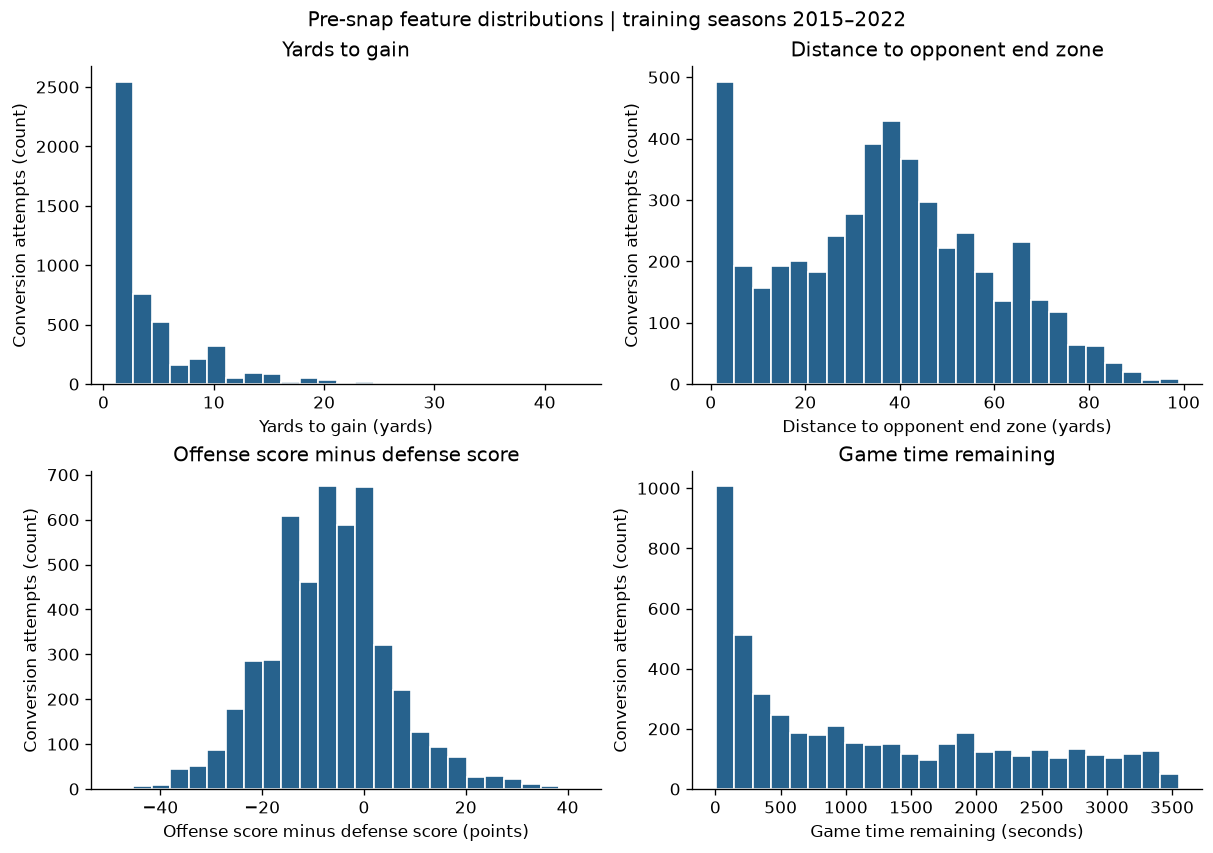

In [5]:
# Cell 8
columns = ["ydstogo", "yardline_100", "score_differential", "game_seconds_remaining"]
x_labels = [
    "Yards to gain (yards)",
    "Distance to opponent end zone (yards)",
    "Offense score minus defense score (points)",
    "Game time remaining (seconds)",
]
titles = [
    "Yards to gain", "Distance to opponent end zone",
    "Offense score minus defense score", "Game time remaining",
]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
axes = axes.flatten()
for i in range(len(columns)):
    values = train[columns[i]].dropna()
    axes[i].hist(values, bins=25, color="#27628d", edgecolor="white")
    axes[i].set_title(titles[i])
    axes[i].set_xlabel(x_labels[i])
    axes[i].set_ylabel("Conversion attempts (count)")
fig.suptitle("Pre-snap feature distributions | training seasons 2015–2022")
fig.savefig(OUT / "01_feature_distributions.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


In [6]:
# Cell 9
short_share = train.ydstogo.le(2).mean()
rate = train.converted.mean()
display(Markdown(f"**Interpretation:** {short_share:.1%} of training attempts need at most two yards. Overall conversion success is {rate:.1%}. The distributions describe selected attempts, not all fourth-down decisions. Retain valid long-distance and late-game observations; assess transformations and nonlinear effects during validation rather than trimming these cases automatically."))


**Interpretation:** 52.1% of training attempts need at most two yards. Overall conversion success is 51.8%. The distributions describe selected attempts, not all fourth-down decisions. Retain valid long-distance and late-game observations; assess transformations and nonlinear effects during validation rather than trimming these cases automatically.

<!-- Cell 10 -->
## Conversion versus distance and field position
Points show observed conversion rates, with 95% Wilson intervals. These intervals describe binomial uncertainty under an independent-play approximation; within-game/team dependence can make them too narrow. Counts identify sparse groups. Associations do not establish causal effects.

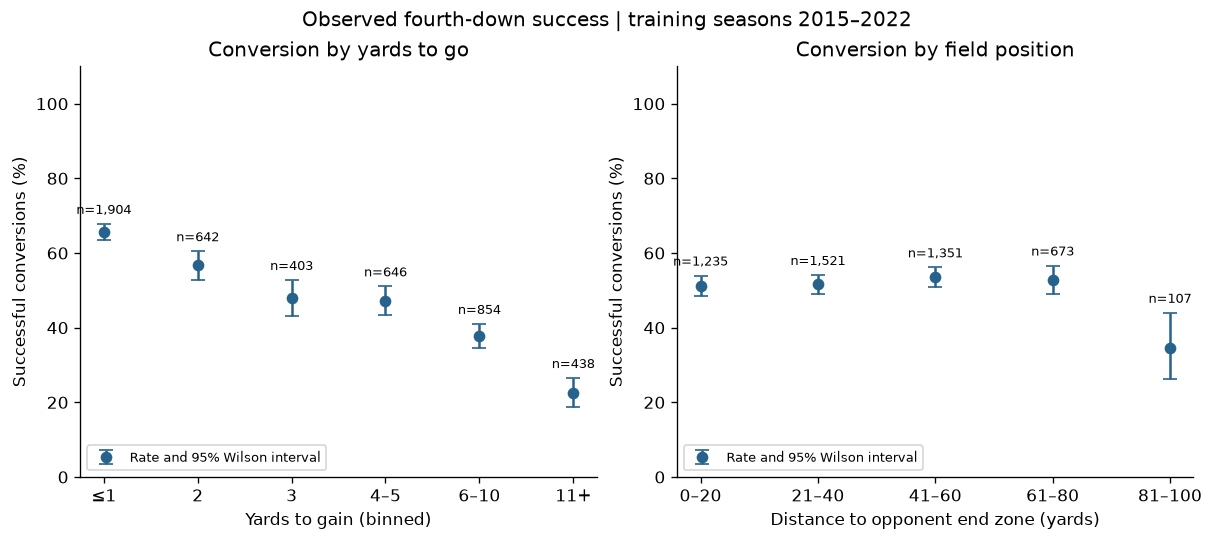

,n,successes,rate,lower,upper
distance_bin,,,,,
≤1,1904,1251,0.657038,0.635418,0.678025
2,642,364,0.566978,0.528363,0.604797
3,403,193,0.478908,0.430564,0.527651
4–5,646,305,0.472136,0.433917,0.510685
6–10,854,322,0.377049,0.345163,0.410037
11+,438,98,0.223744,0.187212,0.265080


,n,successes,rate,lower,upper
field_bin,,,,,
0–20,1235,632,0.511741,0.483869,0.539540
21–40,1521,785,0.516108,0.490984,0.541151
41–60,1351,723,0.535159,0.508501,0.561618
61–80,673,356,0.528975,0.491204,0.566416
81–100,107,37,0.345794,0.262431,0.439846


In [7]:
# Cell 11
# Use the same calculation for distance, field position, and season.
def rate_table(frame, group):
    grouped = frame.groupby(group, observed=False)["converted"]
    result = pd.DataFrame()
    result["n"] = grouped.size()
    result["successes"] = grouped.sum()

    # Empty groups get NaN instead of dividing by zero.
    sample_size = result["n"].replace(0, np.nan)
    result["rate"] = result["successes"] / sample_size
    proportion = result["rate"]

    # Wilson interval for a proportion, using z = 1.96 for 95%.
    z = 1.96
    denominator = 1 + z**2 / sample_size
    center = (proportion + z**2 / (2 * sample_size)) / denominator
    variance_term = proportion * (1 - proportion) / sample_size
    correction = z**2 / (4 * sample_size**2)
    half_width = z * np.sqrt(variance_term + correction) / denominator
    result["lower"] = center - half_width
    result["upper"] = center + half_width
    return result

train["distance_bin"] = pd.cut(train.ydstogo, [-np.inf, 1, 2, 3, 5, 10, np.inf], labels=["≤1", "2", "3", "4–5", "6–10", "11+"])
train["field_bin"] = pd.cut(train.yardline_100, [0, 20, 40, 60, 80, 100], include_lowest=True, labels=["0–20", "21–40", "41–60", "61–80", "81–100"])
distance = rate_table(train, "distance_bin")
field = rate_table(train, "field_bin")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
tables = [distance, field]
titles = ["Conversion by yards to go", "Conversion by field position"]
x_labels = ["Yards to gain (binned)", "Distance to opponent end zone (yards)"]
for plot_number in range(2):
    ax = axes[plot_number]
    table = tables[plot_number]
    title = titles[plot_number]
    xlabel = x_labels[plot_number]
    x = np.arange(len(table))
    lower_error = (table["rate"] - table["lower"]) * 100
    upper_error = (table["upper"] - table["rate"]) * 100
    ax.errorbar(
        x, table["rate"] * 100, yerr=[lower_error, upper_error],
        fmt="o", capsize=4, color="#27628d",
        label="Rate and 95% Wilson interval",
    )
    for i in range(len(table)):
        count = int(table.iloc[i]["n"])
        upper_bound = table.iloc[i]["upper"] * 100
        if count > 0:
            ax.annotate(
                f"n={count:,}", (i, upper_bound), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=8,
            )
    ax.set(xticks=x, xticklabels=table.index.astype(str), ylim=(0, 110), title=title, xlabel=xlabel, ylabel="Successful conversions (%)")
    ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Observed fourth-down success | training seasons 2015–2022")
fig.savefig(OUT / "02_conversion_relationships.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
display(distance, field)
distance.to_csv(OUT / "conversion_by_distance.csv")
field.to_csv(OUT / "conversion_by_field_position.csv")


In [8]:
# Cell 12
display(Markdown(f"**Interpretation:** Conversion rates are {distance.loc['≤1', 'rate']:.1%} for ≤1 yard ({int(distance.loc['≤1', 'n']):,} attempts) and {distance.loc['11+', 'rate']:.1%} for 11+ yards ({int(distance.loc['11+', 'n']):,} attempts). Distance is a useful candidate predictor; compare a simple linear effect with nonlinear models. Field-position rates are unadjusted for distance, team strength, and game situation, so they should not be interpreted as isolated field-position effects."))


**Interpretation:** Conversion rates are 65.7% for ≤1 yard (1,904 attempts) and 22.4% for 11+ yards (438 attempts). Distance is a useful candidate predictor; compare a simple linear effect with nonlinear models. Field-position rates are unadjusted for distance, team strength, and game situation, so they should not be interpreted as isolated field-position effects.

<!-- Cell 13 -->
## Time patterns
Counts below are conversion attempts per season, not the fraction of all fourth downs on which a team goes for it. They also reflect season length and playoff participation. Use chronological validation to assess whether learned relationships transfer to newer seasons.

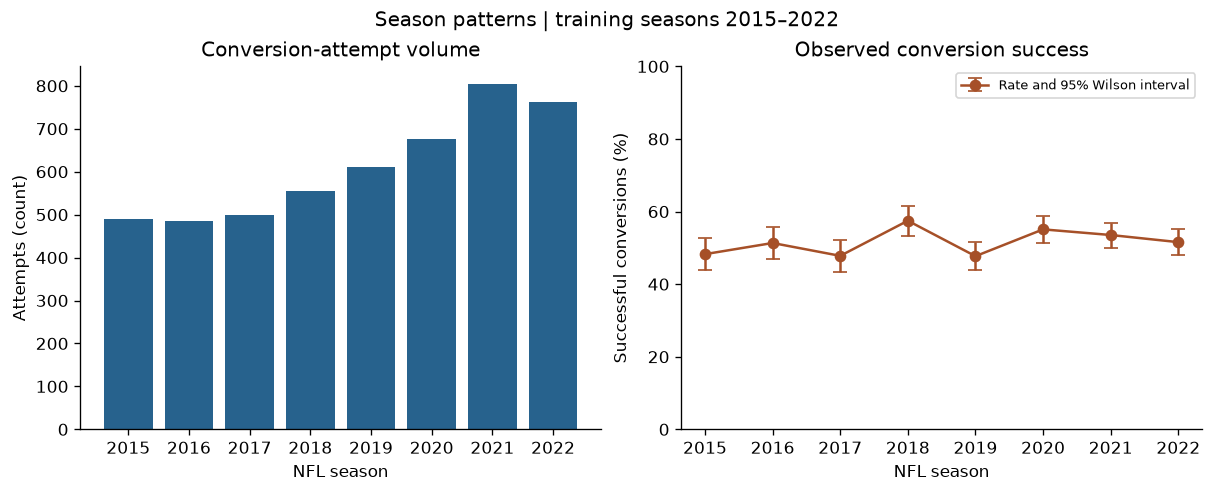

**Interpretation:** Attempt counts change from 491 in 2015 to 762 in 2022. Annual conversion rates range from 47.7% to 57.5%. Counts alone cannot establish that coaches became more aggressive; that requires an all-fourth-down denominator and adjustment for schedule length and game context.

In [9]:
# Cell 14
season = rate_table(train, "season")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].bar(season.index, season.n, color="#27628d")
axes[0].set(title="Conversion-attempt volume", xlabel="NFL season", ylabel="Attempts (count)")
axes[1].errorbar(season.index, season.rate*100, yerr=np.vstack([season.rate-season.lower, season.upper-season.rate])*100, fmt="o-", capsize=4, color="#a65028", label="Rate and 95% Wilson interval")
axes[1].set(title="Observed conversion success", xlabel="NFL season", ylabel="Successful conversions (%)", ylim=(0, 100))
axes[1].legend(fontsize=8)
fig.suptitle("Season patterns | training seasons 2015–2022")
fig.savefig(OUT / "03_season_patterns.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
season.to_csv(OUT / "training_season_summary.csv")
display(Markdown(f"**Interpretation:** Attempt counts change from {int(season.iloc[0].n):,} in 2015 to {int(season.iloc[-1].n):,} in 2022. Annual conversion rates range from {season.rate.min():.1%} to {season.rate.max():.1%}. Counts alone cannot establish that coaches became more aggressive; that requires an all-fourth-down denominator and adjustment for schedule length and game context."))


<!-- Cell 15 -->
## Correlation screen
Pearson correlations screen numeric pre-snap features and the binary target. Correlation with a binary outcome is a point-biserial association. Team categories are omitted; quarter is treated numerically only for this exploratory screen. Correlation is neither model feature importance nor a causal estimate, and it can miss nonlinear effects.

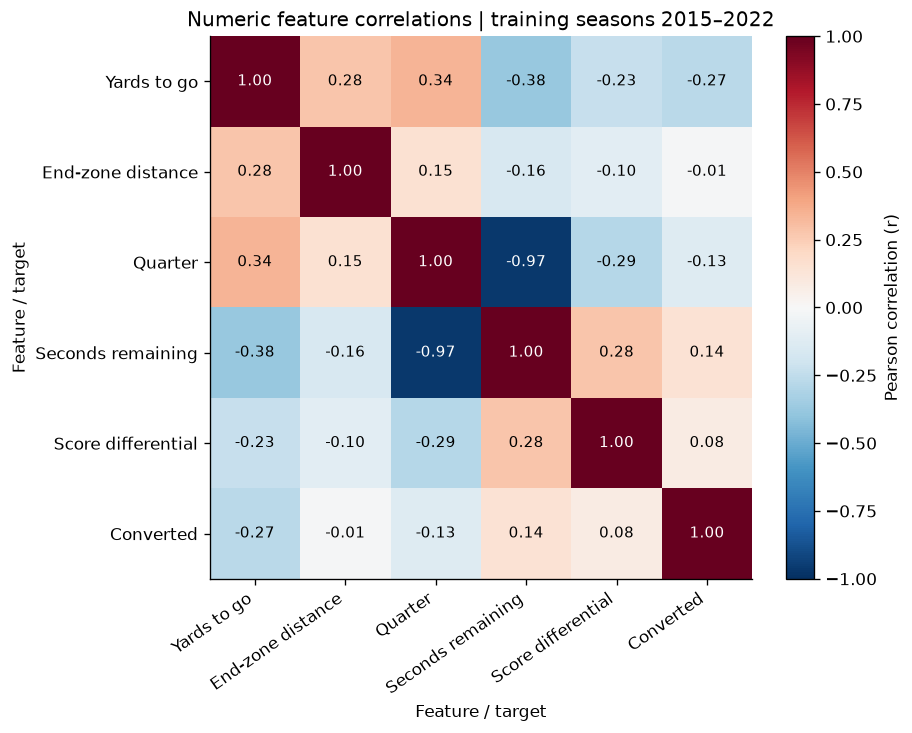

**Interpretation:** The largest absolute numeric association with conversion is `ydstogo` (r=-0.271). Clock and quarter may contain overlapping information. Retain an explicit pre-snap feature list and assess predictive contribution with validation-set permutation importance once a model exists.

In [10]:
# Cell 16
corr = train[NUMERIC + ["converted"]].corr()
labels = ["Yards to go", "End-zone distance", "Quarter", "Seconds remaining", "Score differential", "Converted"]
fig, ax = plt.subplots(figsize=(7.6, 6), layout="constrained")
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=labels, yticklabels=labels, title="Numeric feature correlations | training seasons 2015–2022", xlabel="Feature / target", ylabel="Feature / target")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.iloc[i, j]
        if abs(value) > 0.6:
            text_color = "white"
        else:
            text_color = "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=text_color, fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson correlation (r)")
fig.savefig(OUT / "04_correlations.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
corr.to_csv(OUT / "training_correlations.csv")
strongest = corr["converted"].drop("converted").abs().idxmax()
display(Markdown(f"**Interpretation:** The largest absolute numeric association with conversion is `{strongest}` (r={corr.loc[strongest, 'converted']:.3f}). Clock and quarter may contain overlapping information. Retain an explicit pre-snap feature list and assess predictive contribution with validation-set permutation importance once a model exists."))


<!-- Cell 17 -->
## Data challenges and modeling handoff
- **Selection bias:** These are attempted conversions, not a random sample of all fourth downs. Conclusions concern attempted plays; a punt/kick/go-for-it recommendation needs additional outcome modeling.
- **Penalty policy:** Jordan's filter excludes every flagged penalty, including potentially meaningful plays. Quantify exclusions and consider a separately agreed sensitivity analysis; this notebook preserves the current policy.
- **Leakage:** The retained dataset includes post-play outcomes. Never use all columns as model inputs. Start with `FEATURE_COLUMNS`; exclude conversion flags, yards gained, post-play scores, and other outcome-derived fields.
- **Missingness/outliers:** The audit reports observed issues; this notebook does not impute, scale, or drop further observations. If necessary, fit numeric imputation and scaling on training data only, and encode categorical values with handling for unseen teams. Investigate domain-range flags before modeling.
- **Dependence and drift:** Plays share games and teams; years may differ. Keep games together and consider game-cluster bootstrap intervals for model comparisons.
- **Feature importance:** Correlation screening is completed; model-based importance is pending.

**Suggested handoff:** a training-prevalence reference plus logistic regression baseline, then random forest and gradient boosting candidates. Compare probability quality using log loss, Brier score, and calibration, alongside discrimination metrics. Tune on validation data only. These are suggestions, not completed experiments.

**Contribution:** Logan owns this notebook, its EDA/audits, figure exports, and interpretation text. Jordan owns the shared ingestion/filtering pipeline. Final team assignments and split approval remain to be recorded.

In [11]:
# Cell 18
summary = f"""# Logan EDA evidence for the milestone

Source snapshot: {provenance.get('downloaded_utc')}.
Raw size: {len(raw):,} rows and {raw.shape[1]} columns.
Filtered size: {len(attempts):,} rows and {attempts.shape[1]} columns, including the added target.

Proposed chronological split (pending team agreement):
{splits.to_string(index=False)}

All findings below concern training seasons 2015–2022 only.
- Training conversion rate: {rate:.2%} across {len(train):,} attempts.
- Attempts requiring at most two yards: {short_share:.2%}.
- Conversion rate for ≤1 yard: {distance.loc['≤1', 'rate']:.2%}; 11+ yards: {distance.loc['11+', 'rate']:.2%}.
- Missing entries across proposed training predictors: {int(quality.missing_count.sum()):,}.
- Duplicate training game/play identifiers: {duplicates:,}.
- Domain-range flags (may overlap): {int(range_flags.sum()):,}.
- Largest absolute numeric target correlation: {strongest}, r={corr.loc[strongest, 'converted']:.3f}.

Use 01_feature_distributions, 02_conversion_relationships, and 03_season_patterns as candidate milestone figures; use 04_correlations if space permits. Refer to notebook captions for interpretation and caveats. No model-based importance or model results are claimed.

Limitations: selected conversion attempts; all penalties excluded; unadjusted associations; within-game dependence; proposed split requires team agreement. Conversion probability alone does not answer whether going for it maximizes win probability.
"""
(OUT / "milestone_evidence.md").write_text(summary, encoding="utf-8")
package_versions = {}
for package in ["pandas", "numpy", "matplotlib", "nflreadpy", "pyarrow"]:
    package_versions[package] = version(package)

run_metadata = provenance.copy()
run_metadata["executed_utc"] = datetime.now(timezone.utc).isoformat()
run_metadata["python"] = platform.python_version()
run_metadata["packages"] = package_versions
run_metadata["split_status"] = "proposed; pending team agreement"
run_metadata["eda_seasons"] = list(range(2015, 2023))
(OUT / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
display(Markdown(summary))


# Logan EDA evidence for the milestone

Source snapshot: 2026-10-12T02:04:44.317934+00:00.
Raw size: 532,376 rows and 372 columns.
Filtered size: 7,433 rows and 373 columns, including the added target.

Proposed chronological split (pending team agreement):
     split   seasons  examples  games
  training 2015–2022      4887   1942
validation      2023       823    272
      test 2024–2025      1723    547

All findings below concern training seasons 2015–2022 only.
- Training conversion rate: 51.83% across 4,887 attempts.
- Attempts requiring at most two yards: 52.10%.
- Conversion rate for ≤1 yard: 65.70%; 11+ yards: 22.37%.
- Missing entries across proposed training predictors: 0.
- Duplicate training game/play identifiers: 0.
- Domain-range flags (may overlap): 0.
- Largest absolute numeric target correlation: ydstogo, r=-0.271.

Use 01_feature_distributions, 02_conversion_relationships, and 03_season_patterns as candidate milestone figures; use 04_correlations if space permits. Refer to notebook captions for interpretation and caveats. No model-based importance or model results are claimed.

Limitations: selected conversion attempts; all penalties excluded; unadjusted associations; within-game dependence; proposed split requires team agreement. Conversion probability alone does not answer whether going for it maximizes win probability.
